# Where the plant false positives come from

Each of the 45 standards was injected on its own, so every false-positive (FP) structure can be traced to the injections it appears in. For each FP structure, per tool and score threshold, this notebook records:

- whether it is one of the 6 standards left out of the plant reference file
- whether it has the molecular formula of one of the 45 standards (isomer)
- its highest Tanimoto similarity to any of the 45 standards (Morgan fingerprints, as in notebook 07)
- in how many standards' injections it has signal after the blank filter, and whether it co-elutes with the standard in that injection

Each FP gets one class, the first rule that applies:

1. **Left-out standard**: one of the 6 standards without a reference spectrum
2. **Isomer of a standard**: same molecular formula as a standard
3. **Close analog**: Tanimoto ≥ 0.7 to a standard
4. **One standard only**: signal in the injections of a single standard
5. **Two to four standards**
6. **5 or more standards**: shared background

Outputs: Supplementary Figure 14 (`../figures/supplementary_figure_14.png`) and Supplementary Table 6 (`../data/false_positives/supp_table6_plant_false_positive_classes.csv`).

In [1]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from scipy.stats import spearmanr

from benchmarking.constants import TOOL_COLORS, TOOL_NAMES
from benchmarking.metrics.base_metrics import load_all_feature_tables

RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 200)

In [2]:
TOOLS = ["mzmine", "metaboscape", "msdial"]
THRESHOLDS = (0.7, 0.9)
TANIMOTO_ANALOG = 0.7
COELUTION_MIN = (
    0.1  # RT window (min) for "co-elutes with the standard in its own injection"
)
MANY_STANDARDS = 5

CLASSES = [
    "Left-out standard",
    "Isomer of a standard",
    "Close analog (Tanimoto >= 0.7)",
    "One standard only",
    "Two to four standards",
    f"{MANY_STANDARDS} or more standards",
]

# Standards without a spectrum in the plant reference file (R3 point 1)
LEFT_OUT = {
    "synephrine": "CNCC(O)c1ccc(O)cc1",
    "hydroxytyrosol acetate": "CC(=O)OCCc1ccc(O)c(O)c1",
    "4-hydroxybenzyl alcohol": "OCc1ccc(O)cc1",
    "tropine": "CN1C2CCC1CC(O)C2",
    "oxindole": "O=C1Cc2ccccc2N1",
    "hydroxy-alpha-sanshool": "C/C=C/C=C/C=C\\CC/C=C/C(=O)NCC(C)(C)O",
}

GENERATOR = rdFingerprintGenerator.GetMorganGenerator()


def norm(name: str) -> str:
    return re.sub(r"[^a-z0-9]", "", name.lower())


def run_standard(column: str) -> str:
    """Standard injected in a run, from the run's file name."""
    return norm(re.match(r"SAMPLE_(.+?)_\d+ng_", column).group(1))


def run_amount(column: str) -> int:
    return int(re.match(r"SAMPLE_.+?_(\d+)ng_", column).group(1))

## The 45 standards

Structures come from the plant reference file and are checked against its InChIKeys. The reference file lacks SMILES for 21 standards; those are taken from the local SMILES cache. Supplementary Table 2 is not used, because many of its SMILES are wrong (R3 point 3).

In [3]:
smiles_cache = json.load(open("../data/cache/inchikey_smiles_map.json"))
smiles_cache_14 = {key[:14]: smi for key, smi in smiles_cache.items()}

reference = pd.read_parquet("../data/library_spectra/plant_spikein_lib_with_smiles.pq")
reference = reference.drop_duplicates("inchikey_2d")

rows = []
for _, r in reference.iterrows():
    key14 = r["inchikey_2d"][:14]
    smiles = r["smiles"] if isinstance(r["smiles"], str) else smiles_cache_14.get(key14)
    mol = Chem.MolFromSmiles(smiles)
    assert Chem.MolToInchiKey(mol)[:14] == key14, r["metabolite_name"]
    rows.append(
        {
            "standard": r["metabolite_name"],
            "ik14": key14,
            "mol": mol,
            "in_reference": True,
        }
    )
for name, smiles in LEFT_OUT.items():
    mol = Chem.MolFromSmiles(smiles)
    rows.append(
        {
            "standard": name,
            "ik14": Chem.MolToInchiKey(mol)[:14],
            "mol": mol,
            "in_reference": False,
        }
    )

standards = pd.DataFrame(rows)
standards["key"] = standards["standard"].map(norm)
standards["formula"] = standards["mol"].map(CalcMolFormula)
standards["fingerprint"] = standards["mol"].map(GENERATOR.GetFingerprint)

eval_keys = set(standards.loc[standards["in_reference"], "ik14"])
left_out_keys = set(standards.loc[~standards["in_reference"], "ik14"])
formula_to_standard = (
    standards.groupby("formula")["standard"].apply(", ".join).to_dict()
)
standards_by_key = standards.set_index("key")

len(standards), len(eval_keys)

(45, 39)

## Feature tables (blank-subtracted, as in notebook 06a)

In [4]:
merged_feature_tables = load_all_feature_tables(
    ["../data/groundtruth_dataset/plant_spikein"],
    annotation_subfolder="annotated_spectral_entropy",
    blank_subtracted=True,
)

  0%|          | 0/1 [00:00<?, ?it/s]

Blank subtraction (mzmine, plant_spikein): kept 37,465/64,679 features (57.9%)


100%|██████████| 1/1 [00:00<00:00,  1.45it/s]

Blank subtraction (metaboscape, plant_spikein): kept 18,744/26,872 features (69.8%)
Blank subtraction (msdial, plant_spikein): kept 7,487/23,907 features (31.3%)


## Classify each false-positive structure

A false positive is a structure annotated at or above the threshold whose InChIKey first block is not among the 39 standards in the reference file, exactly as in Figure 5B.

In [5]:
def standard_retention_times(ann: pd.DataFrame, runs: list) -> dict:
    """RT of each standard in its own injections: its most intense feature annotated as the standard."""
    rts = {}
    for key, s in standards_by_key.iterrows():
        own = [c for c in runs if run_standard(c) == key]
        hits = ann[ann["ik14"] == s["ik14"]]
        if own and len(hits):
            top = hits.loc[hits[own].fillna(0).max(axis=1).idxmax()]
            if top[own].fillna(0).max() > 0:
                rts[key] = float(top["RT"])
    return rts


rows = []
for tool in TOOLS:
    df = merged_feature_tables[tool]
    runs = [c for c in df.columns if c.startswith("SAMPLE_")]
    ann = df[df["SCORE"].notna()].copy()
    ann["ik14"] = ann["INCHIKEY"].astype(str).str[:14]
    heights = ann[runs].fillna(0)
    std_rt = standard_retention_times(ann, runs)

    for threshold in THRESHOLDS:
        selected = ann[ann["SCORE"] >= threshold]
        false_positives = selected[~selected["ik14"].isin(eval_keys)]
        for ik14, group in false_positives.groupby("ik14"):
            h = heights.loc[group.index]
            present = h.columns[(h > 0).any(axis=0)]
            n_standards = len({run_standard(c) for c in present})
            top_run = h.max(axis=0).idxmax()
            top_standard = run_standard(top_run)
            rt = float(group.loc[h[top_run].idxmax(), "RT"])
            coelutes = (
                top_standard in std_rt
                and abs(rt - std_rt[top_standard]) <= COELUTION_MIN
            )

            full_key = group["INCHIKEY"].iloc[0]
            smiles = smiles_cache.get(full_key) or smiles_cache_14.get(ik14)
            mol = Chem.MolFromSmiles(smiles) if smiles else None
            if mol is not None:
                formula = CalcMolFormula(mol)
                sims = DataStructs.BulkTanimotoSimilarity(
                    GENERATOR.GetFingerprint(mol), list(standards["fingerprint"])
                )
                best = int(np.argmax(sims))
                tanimoto, nearest = float(sims[best]), standards["standard"].iloc[best]
            else:
                formula, tanimoto, nearest = None, np.nan, None

            if ik14 in left_out_keys:
                fp_class = CLASSES[0]
            elif formula in formula_to_standard:
                fp_class = CLASSES[1]
            elif tanimoto >= TANIMOTO_ANALOG:
                fp_class = CLASSES[2]
            elif n_standards == 1:
                fp_class = CLASSES[3]
            elif n_standards < MANY_STANDARDS:
                fp_class = CLASSES[4]
            else:
                fp_class = CLASSES[5]

            rows.append(
                {
                    "tool": TOOL_NAMES[tool],
                    "threshold": threshold,
                    "inchikey14": ik14,
                    "inchikey": full_key,
                    "best_score": round(float(group["SCORE"].max()), 3),
                    "n_features": len(group),
                    "structure_resolved": mol is not None,
                    "formula": formula,
                    "isomer_of_standard": formula_to_standard.get(formula, ""),
                    "nearest_standard": nearest,
                    "max_tanimoto": round(tanimoto, 3),
                    "n_standards_with_signal": n_standards,
                    "standard_with_most_signal": standards_by_key.loc[
                        top_standard, "standard"
                    ],
                    "rt_min": round(rt, 2),
                    "coelutes_with_that_standard": coelutes,
                    "fp_class": fp_class,
                }
            )

fp_table = pd.DataFrame(rows)
reframe = pd.read_parquet("../data/library_spectra/reframe_spikein_lib.pq")
fp_table["in_reframe_drug_set"] = fp_table["inchikey14"].isin(
    set(reframe["inchikey_2d"].str[:14])
)
fp_table.to_csv(
    "../data/false_positives/supp_table6_plant_false_positive_classes.csv", index=False
)
fp_table.head()

/var/folders/x2/1tdvwk7x2_n98kzwy7rnt3t00000gn/T/ipykernel_23190/1063128164.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  if top[own].fillna(0).max() > 0:
/var/folders/x2/1tdvwk7x2_n98kzwy7rnt3t00000gn/T/ipykernel_23190/1063128164.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  if top[own].fillna(0).max() > 0:
/var/folders/x2/1tdvwk7x2_n98kzwy7rnt3t00000gn/T/ipykernel_23190/1063128164.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

,tool,threshold,inchikey14,inchikey,best_score,n_features,structure_resolved,formula,isomer_of_standard,nearest_standard,max_tanimoto,n_standards_with_signal,standard_with_most_signal,rt_min,coelutes_with_that_standard,fp_class,in_reframe_drug_set
0,MZmine,0.7,AANNAPQFFOIMQA,AANNAPQFFOIMQA-UHFFFAOYSA-N,0.703,1,True,C15H15NO5,,catharanthine,0.140,2,dihydrochelerythrine,4.09,False,Two to four standards,False
1,MZmine,0.7,ABRULANJVVJLFI,ABRULANJVVJLFI-UHFFFAOYSA-N,0.747,1,True,C22H22O10,,visnagin,0.173,1,cryptotanshinone,4.24,False,One standard only,False
2,MZmine,0.7,ABXZOXDTHTTZJW,ABXZOXDTHTTZJW-UHFFFAOYSA-N,0.707,2,True,C16H17NO4,,hydroxytyrosol acetate,0.229,1,hydroxytyrosol acetate,3.71,False,One standard only,False
3,MZmine,0.7,ACVGWSKVRYFWRP,ACVGWSKVRYFWRP-UHFFFAOYSA-N,0.748,1,True,C18H13N3O,,catharanthine,0.234,2,dehydroevodiamine,5.33,False,Two to four standards,False
4,MZmine,0.7,ADZBMFGQQWPHMJ,ADZBMFGQQWPHMJ-UHFFFAOYSA-N,0.892,1,False,None,,None,NaN,1,cryptotanshinone,4.98,False,One standard only,True


The totals match Figure 5B (272 / 275 / 102 at 0.7; 29 / 27 / 5 at 0.9).

In [6]:
class_counts = (
    fp_table.groupby(["threshold", "tool"])["fp_class"]
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=CLASSES, fill_value=0)
)
class_counts["total"] = class_counts.sum(axis=1)
class_counts

fp_class               Left-out standard  Isomer of a standard  Close analog (Tanimoto >= 0.7)  One standard only  Two to four standards  5 or more standards  total
threshold tool                                                                                                                                                      
0.7       MS-DIAL                      0                     1                               0                 42                     18                   41    102
          MZmine                       1                     5                               1                115                     79                   71    272
          MetaboScape                  0                     8                               1                152                     68                   46    275
0.9       MS-DIAL                      0                     0                               0                  1                      1                    3      5
          MZmine                       0                     1                               0                 15                      6                    7     29
          MetaboScape                  0                     2                               0                 14                      8                    3     27

## Are the false positives related to the standards?

Very few are a standard, an isomer or a close analog; the median highest Tanimoto similarity to any of the 45 standards is below 0.2. Structures that could not be resolved from their InChIKey are counted by injection pattern only.

In [7]:
fp_table.groupby(["threshold", "tool"]).agg(
    median_max_tanimoto=("max_tanimoto", "median"),
    related_to_a_standard=("fp_class", lambda s: int(s.isin(CLASSES[:3]).sum())),
    structure_not_resolved=("structure_resolved", lambda s: int((~s).sum())),
)

median_max_tanimoto  related_to_a_standard  structure_not_resolved
threshold tool                                                                           
0.7       MS-DIAL                   0.1710                      1                      26
          MZmine                    0.1600                      7                      54
          MetaboScape               0.1705                      9                      49
0.9       MS-DIAL                   0.1880                      0                       0
          MZmine                    0.1685                      1                       5
          MetaboScape               0.1725                      2                       7

## One standard only: do they come in with the standard?

For FPs seen in the injections of a single standard, two checks:

- **Co-elution** with the standard in its own injection would point to adducts or in-source fragments of the standard. Few co-elute.
- **Amount**: 19 standards were also injected at 100 and 200 ng. If an FP's signal rises across 50, 100 and 200 ng, it came in with that standard's solution. Chance gives a strictly rising order about 1 time in 6.

In [8]:
one = fp_table[fp_table["fp_class"] == "One standard only"]
one.groupby(["threshold", "tool"])["coelutes_with_that_standard"].agg(
    coeluting="sum", one_standard_only="size"
)

coeluting  one_standard_only
threshold tool                                     
0.7       MS-DIAL              1                 42
          MZmine               6                115
          MetaboScape         12                152
0.9       MS-DIAL              0                  1
          MZmine               1                 15
          MetaboScape          2                 14

In [9]:
def rises_with_amount(ann: pd.DataFrame, runs: list, keys) -> list:
    by_standard = {}
    for c in runs:
        by_standard.setdefault(run_standard(c), []).append(c)
    three = {
        s: sorted(cs, key=run_amount) for s, cs in by_standard.items() if len(cs) == 3
    }
    out = []
    for key in keys:
        h = ann.loc[ann["ik14"] == key, runs].fillna(0)
        if h.values.max() <= 0:
            continue
        s = run_standard(h.max(axis=0).idxmax())
        if s in three:
            values = h[three[s]].max(axis=0).to_numpy(float)
            out.append(spearmanr([50, 100, 200], values)[0] > 0.99)
    return out


amount_rows = []
for tool in TOOLS:
    df = merged_feature_tables[tool]
    runs = [c for c in df.columns if c.startswith("SAMPLE_")]
    ann = df[df["SCORE"].notna() & (df["SCORE"] >= 0.7)].copy()
    ann["ik14"] = ann["INCHIKEY"].astype(str).str[:14]
    keys = one.loc[
        (one["tool"] == TOOL_NAMES[tool]) & (one["threshold"] == 0.7), "inchikey14"
    ]
    fps = rises_with_amount(ann, runs, keys)
    stds = rises_with_amount(ann, runs, eval_keys & set(ann["ik14"]))
    amount_rows.append(
        {
            "tool": TOOL_NAMES[tool],
            "one_standard_fps_tested": len(fps),
            "fps_rising_with_amount": int(sum(fps)),
            "standards_tested": len(stds),
            "standards_rising_with_amount": int(sum(stds)),
        }
    )
pd.DataFrame(amount_rows)

,tool,one_standard_fps_tested,fps_rising_with_amount,standards_tested,standards_rising_with_amount
0,MZmine,71,40,13,10
1,MetaboScape,83,41,13,9
2,MS-DIAL,27,14,10,6


They cluster in a few standards, and a share of them are drugs from the ReFRAME library, which was run on the same instrument.

In [10]:
at_07 = fp_table[fp_table["threshold"] == 0.7]
(
    at_07[at_07["fp_class"] == "One standard only"]
    .groupby("tool")["standard_with_most_signal"]
    .value_counts()
    .groupby(level=0)
    .head(5)
)

tool         standard_with_most_signal
MS-DIAL      cryptotanshinone             14
             catharanthine                 4
             hydroxy-alpha-sanshool        4
             dihydrochelerythrine          3
             dehydroevodiamine             2
MZmine       cryptotanshinone             26
             hydroxy-alpha-sanshool       14
             dihydrochelerythrine         11
             catharanthine                10
             oxindole                      6
MetaboScape  cryptotanshinone             34
             dihydrochelerythrine         13
             hydroxy-alpha-sanshool       12
             catharanthine                11
             dehydronuciferine             6
Name: count, dtype: int64

In [11]:
at_07.groupby(["tool", "fp_class"])["in_reframe_drug_set"].sum().unstack(fill_value=0)

fp_class,5 or more standards,Close analog (Tanimoto >= 0.7),Isomer of a standard,Left-out standard,One standard only,Two to four standards
tool,,,,,,
MS-DIAL,2,0,0,0,7,0
MZmine,2,0,0,0,17,5
MetaboScape,3,0,0,0,14,3


## Supplementary Figure 14

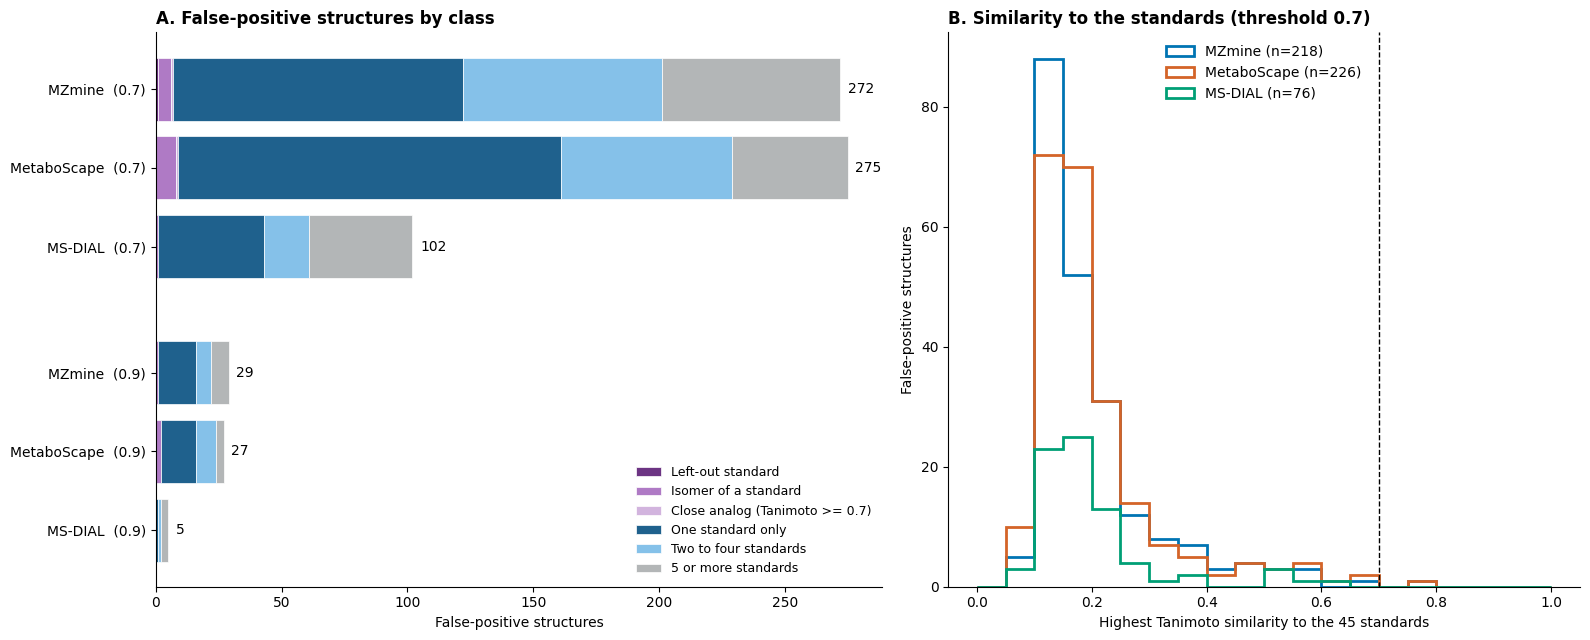

In [12]:
palette = ["#6C3483", "#AF7AC5", "#D2B4DE", "#1F618D", "#85C1E9", "#B3B6B7"]
fig, axes = plt.subplots(
    1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]}
)

# A. Classes per tool and threshold
ax = axes[0]
labels, ypos = [], []
for i, threshold in enumerate(THRESHOLDS):
    for j, tool in enumerate(TOOLS):
        labels.append(f"{TOOL_NAMES[tool]}  ({threshold})")
        ypos.append(i * 3.6 + j)
left = np.zeros(len(ypos))
for k, fp_class in enumerate(CLASSES):
    values = np.array(
        [
            class_counts.loc[(t, TOOL_NAMES[tool]), fp_class]
            for t in THRESHOLDS
            for tool in TOOLS
        ]
    )
    ax.barh(
        ypos,
        values,
        left=left,
        color=palette[k],
        label=fp_class,
        edgecolor="white",
        linewidth=0.5,
    )
    left += values
for y, total in zip(ypos, left):
    ax.text(total + 3, y, str(int(total)), va="center", fontsize=10)
ax.set_yticks(ypos, labels)
ax.invert_yaxis()
ax.set_xlabel("False-positive structures")
ax.set_title("A. False-positive structures by class", loc="left", fontweight="bold")
ax.legend(fontsize=9, frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

# B. Highest Tanimoto similarity to the 45 standards
ax = axes[1]
bins = np.linspace(0, 1, 21)
for tool in TOOLS:
    values = at_07.loc[at_07["tool"] == TOOL_NAMES[tool], "max_tanimoto"].dropna()
    ax.hist(
        values,
        bins=bins,
        histtype="step",
        linewidth=2,
        color=TOOL_COLORS[tool],
        label=f"{TOOL_NAMES[tool]} (n={len(values)})",
    )
ax.axvline(TANIMOTO_ANALOG, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Highest Tanimoto similarity to the 45 standards")
ax.set_ylabel("False-positive structures")
ax.set_title(
    "B. Similarity to the standards (threshold 0.7)", loc="left", fontweight="bold"
)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("../figures/supplementary_figure_14.png", dpi=300, bbox_inches="tight")
plt.show()